In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
data_dir = "/content/drive/MyDrive/ratings.csv"

In [25]:
import numpy as np
import pandas as pd
from numba import njit, prange
from scipy.sparse import coo_matrix


dtypes = {"userId":"int32", "movieId":"int32", "rating":"float32"}
df = pd.read_csv(data_dir, usecols=['userId', 'movieId', 'rating'], dtype=dtypes)

# Vectorized mappings

unique_users, user_indices = np.unique(df['userId'].values, return_inverse=True)
unique_items, item_indices = np.unique(df['movieId'].values, return_inverse=True)
ratings = df['rating'].values

n_users = len(unique_users)
n_items = len(unique_items)

print(f"Number of users: {n_users}")
print(f"Number of items: {n_items}")


Number of users: 200948
Number of items: 84432


In [26]:
rng = np.random.default_rng(42)
random_values = rng.random(len(ratings))
train_mask = random_values < 0.8
test_mask = ~train_mask

train_matrix_user = coo_matrix((ratings[train_mask], (user_indices[train_mask], item_indices[train_mask])), shape=(n_users,n_items)).tocsr()
test_matrix_user = coo_matrix((ratings[test_mask], (user_indices[test_mask], item_indices[test_mask])), shape=(n_users,n_items)).tocsr()
train_matrix_item = coo_matrix((ratings[train_mask], (item_indices[train_mask], user_indices[train_mask])), shape=(n_items,n_users)).tocsr()

In [27]:
train_user_indptr = train_matrix_user.indptr
train_user_indices = train_matrix_user.indices
train_user_data = train_matrix_user.data

test_user_indptr = test_matrix_user.indptr
test_user_indices = test_matrix_user.indices
test_user_data = test_matrix_user.data

train_item_indptr = train_matrix_item.indptr
train_item_indices = train_matrix_item.indices
train_item_data = train_matrix_item.data

global_average = np.float32(np.mean(train_user_data))

In [28]:
print(train_user_indptr.shape)
print(train_user_indices.shape)
print(train_user_data.shape)

(200949,)
(25601250,)
(25601250,)


In [29]:
print(test_user_indptr.shape)
print(test_user_indices.shape)
print(test_user_data.shape)

(200949,)
(6398954,)
(6398954,)


In [30]:
for i in range(10):
  print(train_user_indptr[i], train_user_indices[i], train_user_data[i])


0 16 4.0
121 24 1.0
160 29 5.0
276 31 5.0
299 35 1.0
325 79 5.0
343 108 3.0
377 109 5.0
408 159 1.0
453 174 4.0


In [31]:
@njit(parallel=True, fastmath=True)
def als_algorithm(user_indptr, user_indices, user_data,
    item_indptr, item_indices, item_data,
    U, V, user_bias, item_bias, global_average,
    lam, gamma, tau, U_reg, V_reg, I, k):
	n_users = len(user_indptr) - 1
	n_items = len(item_indptr) - 1

	for m in prange(n_users):
		start_idx = user_indptr[m]
		end_idx = user_indptr[m+1]
		item_counter = end_idx - start_idx
		if item_counter == 0:
			user_bias[m] = 0
			continue

		numerator = 0.0
		for i in range(start_idx, end_idx):
			n = user_indices[i]
			r = user_data[i]

			dot_product = 0.0
			for j in range(k):
				dot_product += U[m,j] * V[n,j]
			numerator += lam * (r - global_average - item_bias[n] - dot_product)

		denominator = lam * item_counter + gamma
		user_bias[m] = numerator / denominator



	for m in prange(n_users):
		start_idx = user_indptr[m]
		end_idx = user_indptr[m+1]
		if start_idx == end_idx:
			U[m, :] = 0.0
			continue
		A = np.zeros((k, k), dtype=np.float32)
		b = np.zeros(k, dtype=np.float32)
		for i in range(start_idx, end_idx):
			n = user_indices[i]
			r = user_data[i]
			# Remove the biases before fitting latent factors.
			residual = (r - global_average - user_bias[m] - item_bias[n])
			for r_idx in range(k):
				V_r = V[n,r_idx]
				b[r_idx] += np.float32(lam * V_r * residual)
				for c_idx in range(k):
					A[r_idx,c_idx] += np.float32(lam * V_r * V[n,c_idx])
		# L2 regularization for User factors.
		for r_idx in range(k):
			A[r_idx,r_idx] += U_reg
		U[m, :] = np.linalg.solve(A, b)



	for n in prange(n_items):
		start_idx = item_indptr[n]
		end_idx = item_indptr[n+1]
		user_counter = end_idx - start_idx
		if user_counter == 0:
			item_bias[n] = 0
			continue

		numerator = 0.0
		for i in range(start_idx, end_idx):
			m = item_indices[i]
			r = item_data[i]

			dot_product = 0.0
			for j in range(k):
				dot_product += U[m,j] * V[n,j]
			numerator += lam * (r - global_average - user_bias[m] - dot_product)

		denominator = lam * user_counter + gamma
		item_bias[n] = numerator / denominator



	for n in prange(n_items):
		start_idx = item_indptr[n]
		end_idx = item_indptr[n+1]
		if start_idx == end_idx:
			V[n, :] = 0.0
			continue
		A = np.zeros((k, k), dtype=np.float32)
		b = np.zeros(k, dtype=np.float32)
		for i in range(start_idx, end_idx):
			m = item_indices[i]
			r = item_data[i]
			residual = (r - global_average - user_bias[m] - item_bias[n])
			for r_idx in range(k):
				U_r = U[m,r_idx]
				b[r_idx] += np.float32(lam * U_r * residual)
				for c_idx in range(k):
					A[r_idx,c_idx] += np.float32(lam * U_r * U[m,c_idx])
		# L2 regularization for item factors.
		for r_idx in range(k):
			A[r_idx,r_idx] += V_reg
		V[n, :] = np.linalg.solve(A, b)





In [32]:
@njit(parallel=True)
def calculate_sse(
    user_indptr, user_data, user_indices,
    U, V, user_bias, item_bias, global_average
):
    n_users = len(user_indptr) - 1

    # Each parallel iteration writes to its own array element.
    user_sse = np.zeros(n_users, dtype=np.float64)
    user_counts = np.zeros(n_users, dtype=np.int64)

    k = U.shape[1]

    for m in prange(n_users):
        start_idx = user_indptr[m]
        end_idx = user_indptr[m + 1]

        local_sse = 0.0
        local_count = 0

        for i in range(start_idx, end_idx):
            n = user_indices[i]
            rating = user_data[i]

            prediction = (
                global_average
                + user_bias[m]
                + item_bias[n]
            )

            for j in range(k):
                prediction += U[m, j] * V[n, j]

            error = rating - prediction
            local_sse += error * error
            local_count += 1

        user_sse[m] = local_sse
        user_counts[m] = local_count

    total_sse = np.sum(user_sse)
    total_count = np.sum(user_counts)

    return total_sse, total_count


In [33]:
lam = 0.01
gamma = 0.1
tau = 0.1
epochs = 30

user_bias = np.zeros(n_users, dtype=np.float32)
item_bias = np.zeros(n_items, dtype=np.float32)

k = 12
U_reg = 0.1
V_reg = 0.1
rng = np.random.default_rng(42)

U = rng.normal(0, 0.01, (n_users, k)).astype(np.float32)
V = rng.normal(0, 0.01, (n_items, k)).astype(np.float32)
I = np.eye(k, dtype=np.float32)

train_loss, test_loss = [], []
train_rmse, test_rmse = [], []


for epoch in range(epochs):
  als_algorithm(train_user_indptr, train_user_indices, train_user_data,
    train_item_indptr, train_item_indices, train_item_data,
    U, V, user_bias, item_bias, global_average,
    lam, gamma, tau, U_reg, V_reg, I, k)

  train_sse, train_count = calculate_sse(train_user_indptr, train_user_data, train_user_indices, U, V, user_bias, item_bias, global_average)
  test_sse, test_count = calculate_sse(test_user_indptr, test_user_data, test_user_indices, U, V, user_bias, item_bias, global_average)

  train_mse = train_sse / train_count
  test_mse = test_sse / test_count

  train_rmse_value = np.sqrt(train_mse)
  test_rmse_value = np.sqrt(test_mse)

  regularization = (
        gamma * np.sum(user_bias.astype(np.float64) ** 2)
        + tau * np.sum(item_bias.astype(np.float64) ** 2)
        + U_reg * np.sum(U.astype(np.float64) ** 2)
        + V_reg * np.sum(V.astype(np.float64) ** 2)
    )


  objective = lam * train_sse + regularization

  train_loss.append(train_mse)
  test_loss.append(test_mse)
  train_rmse.append(train_rmse_value)
  test_rmse.append(test_rmse_value)

  print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_mse:.4f} | Test Loss: {test_mse:.4f} | "
        f"Train RMSE: {train_rmse_value:.4f} | Test RMSE: {test_rmse_value:.4f} | "
        f"Objective: {objective:.4f}"
    )




Epoch 1/30 | Train Loss: 0.7266 | Test Loss: 0.7504 | Train RMSE: 0.8524 | Test RMSE: 0.8663 | Objective: 191715.0112
Epoch 2/30 | Train Loss: 0.5743 | Test Loss: 0.6946 | Train RMSE: 0.7578 | Test RMSE: 0.8334 | Objective: 156581.9504
Epoch 3/30 | Train Loss: 0.5370 | Test Loss: 0.6544 | Train RMSE: 0.7328 | Test RMSE: 0.8089 | Objective: 148000.5459
Epoch 4/30 | Train Loss: 0.5201 | Test Loss: 0.6348 | Train RMSE: 0.7212 | Test RMSE: 0.7968 | Objective: 144179.7314
Epoch 5/30 | Train Loss: 0.5112 | Test Loss: 0.6241 | Train RMSE: 0.7150 | Test RMSE: 0.7900 | Objective: 142152.8100
Epoch 6/30 | Train Loss: 0.5060 | Test Loss: 0.6178 | Train RMSE: 0.7114 | Test RMSE: 0.7860 | Objective: 140973.4670
Epoch 7/30 | Train Loss: 0.5028 | Test Loss: 0.6138 | Train RMSE: 0.7091 | Test RMSE: 0.7835 | Objective: 140228.2925
Epoch 8/30 | Train Loss: 0.5007 | Test Loss: 0.6112 | Train RMSE: 0.7076 | Test RMSE: 0.7818 | Objective: 139730.1974
Epoch 9/30 | Train Loss: 0.4993 | Test Loss: 0.6093 | Tr

In [34]:
np.savez_compressed(
  "/content/drive/MyDrive/als_model_weights.npz",
  U=U,
  V=V,
  user_bias=user_bias,
  item_bias=item_bias,
  global_average=global_average,
  unique_users=unique_users,
  unique_items=unique_items,
)

print("Model weights successfully saved to '/content/drive/MyDrive/als_model_weights.npz'")


Model weights successfully saved to '/content/drive/MyDrive/als_model_weights.npz'


In [35]:
def save_svg(filename):
    plt.savefig(filename + ".svg", format="svg", bbox_inches="tight")

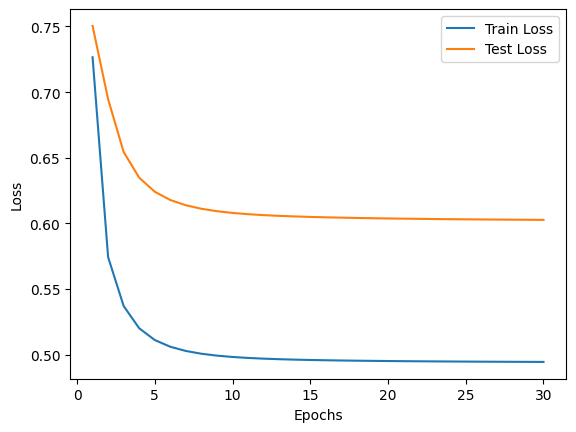

In [36]:
import matplotlib.pyplot as plt

epoch_list = []
for epoch in range(epochs):
  epoch_list.append(epoch+1)

plt.plot(epoch_list, train_loss, label="Train Loss")
plt.plot(epoch_list, test_loss, label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
save_svg("32m_loss")
plt.show()



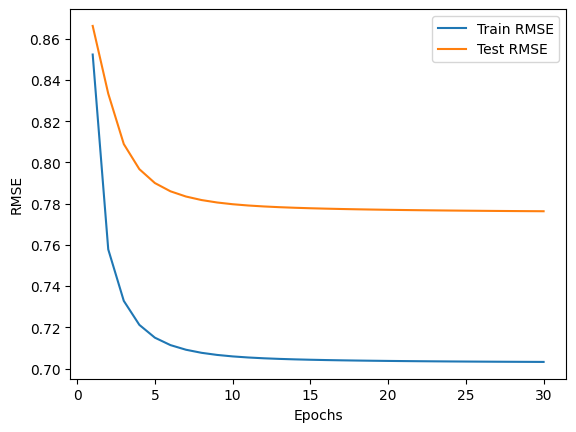

In [37]:
plt.plot(epoch_list, train_rmse, label="Train RMSE")
plt.plot(epoch_list, test_rmse, label="Test RMSE")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
save_svg("32m_rmse")
plt.show()


In [38]:
weights= np.load("/content/drive/MyDrive/als_model_weights.npz")

U = weights["U"]
V = weights["V"]
user_bias = weights["user_bias"]
item_bias = weights["item_bias"]
global_average = weights["global_average"]
unique_users = weights["unique_users"]
unique_items = weights["unique_items"]

user_to_index = {raw_id: index for index, raw_id in enumerate(unique_users)}
index_to_user = {index: raw_id for index, raw_id in enumerate(unique_users)}
item_to_index = {raw_id: index for index, raw_id in enumerate(unique_items)}
index_to_item = {index: raw_id for index, raw_id in enumerate(unique_items)}


In [39]:
U.shape[1]

12

In [40]:
movies_df = pd.read_csv("/content/drive/MyDrive/movies.csv")

# Raw movie ID -> movie title
movie_title_by_id = dict(
    zip(movies_df["movieId"], movies_df["title"])
)

# Raw movie ID -> list of genres
genres_by_id = {
    row["movieId"]: row["genres"].split("|")
    for _, row in movies_df.iterrows()
}

# Keep only movies that have trained item vectors
index_to_movie_id = {
    index: int(movie_id)
    for index, movie_id in enumerate(unique_items)
}

movie_id_to_index = {
    movie_id: index
    for index, movie_id in index_to_movie_id.items()
}

print("Number of movies with trained vectors:", len(index_to_movie_id))
print(movie_title_by_id.get(1))

Number of movies with trained vectors: 84432
Toy Story (1995)


In [41]:
import time
def benchmark_recommendation_speed(dummy_U, dummy_bias=0.0):
    k = V.shape[1]

    # Naive implementation: calculate each movie score individually
    start = time.perf_counter()

    naive_scores = np.empty(V.shape[0])

    for idx in range(V.shape[0]):
        naive_scores[idx] = (
            float(global_average)
            + item_bias[idx]
            + dummy_bias
            + np.dot(V[idx], dummy_U)
        )

    naive_time = time.perf_counter() - start

    # Vectorized implementation: calculate all scores together
    start = time.perf_counter()

    vectorized_scores = (
        float(global_average)
        + item_bias
        + dummy_bias
        + V @ dummy_U
    )

    vectorized_time = time.perf_counter() - start

    print(f"Naive time:      {naive_time:.6f} seconds")
    print(f"Vectorized time: {vectorized_time:.6f} seconds")

    if vectorized_time > 0:
        print(
            f"Speed-up: {naive_time / vectorized_time:.2f}x"
        )

    print(
        "Maximum score difference:",
        np.max(np.abs(naive_scores - vectorized_scores))
    )

In [42]:
def recommend_for_dummy_user(
    liked_movie,
    assigned_rating=5.0,
    top_movies_no=10,
    reg_user_bias=0.5,
    reg_user_factors=0.1
):

    # Find the movie's raw ID
    matching_ids = [
        movie_id
        for movie_id, title in movie_title_by_id.items()
        if title.lower() == liked_movie.lower()
    ]

    if not matching_ids:
        print("Movie not found in movies.csv:", liked_movie)
        return

    movie_id = matching_ids[0]

    if movie_id not in movie_id_to_index:
        print("This movie has no trained item vector:", liked_movie)
        return

    liked_idx = movie_id_to_index[movie_id]
    k = V.shape[1]

    # The dummy user's unknown parameters are:
    # [user_bias, latent_factor_1, latent_factor_2]
    x = np.concatenate(([1.0], V[liked_idx])).astype(float)

    residual = (
        assigned_rating
        - float(global_average)
        - float(item_bias[liked_idx])
    )

    regularization = np.diag(
        [reg_user_bias] + [reg_user_factors] * k
    )

    A = x[:, None] @ x[None, :] + regularization
    b = x * residual

    dummy_parameters = np.linalg.solve(A, b)

    dummy_bias = dummy_parameters[0]
    dummy_U = dummy_parameters[1:]
    benchmark_recommendation_speed(dummy_U, dummy_bias)

    # Score every movie with the trained model
    scores = (
        float(global_average)
        + item_bias
        + dummy_bias
        + V @ dummy_U
    )

    # Do not recommend the movie already rated
    scores[liked_idx] = -np.inf

    # Select the highest-scoring movies
    top_count = min(top_movies_no, len(scores) - 1)
    top_indices = np.argsort(scores)[-top_count:][::-1]

    print(f"\n\nDummy user rated {liked_movie} {assigned_rating}/5")
    print("\nRecommended movies:")
    print("\tTitle\t|\tGenre\t\t|\t\tPredicted Rating")
    print("\n")

    for idx in top_indices:
        recommended_id = index_to_movie_id[idx]
        title = movie_title_by_id.get(recommended_id, "Unknown title")
        genres = genres_by_id.get(recommended_id, [])

        print(
            f"{title} | {', '.join(genres)} "
            f"| {scores[idx]:.3f}"
        )


recommend_for_dummy_user(
    "Toy Story (1995)",
    assigned_rating=5.0,
    top_movies_no=10
)

Naive time:      0.240508 seconds
Vectorized time: 0.017731 seconds
Speed-up: 13.56x
Maximum score difference: 8.881784197001252e-16


Dummy user rated Toy Story (1995) 5.0/5

Recommended movies:
	Title	|	Genre		|		Predicted Rating


Toy Story 3 (2010) | Adventure, Animation, Children, Comedy, Fantasy, IMAX | 4.903
Toy Story 2 (1999) | Adventure, Animation, Children, Comedy, Fantasy | 4.847
Incredibles, The (2004) | Action, Adventure, Animation, Children, Comedy | 4.830
Finding Nemo (2003) | Adventure, Animation, Children, Comedy | 4.827
Monsters, Inc. (2001) | Adventure, Animation, Children, Comedy, Fantasy | 4.800
WALL·E (2008) | Adventure, Animation, Children, Romance, Sci-Fi | 4.796
Up (2009) | Adventure, Animation, Children, Drama | 4.787
Lion King, The (1994) | Adventure, Animation, Children, Drama, Musical, IMAX | 4.770
Inside Out (2015) | Adventure, Animation, Children, Comedy, Drama, Fantasy | 4.737
Planet Earth (2006) | Documentary | 4.728


In [43]:
ratings_data = pd.read_csv("/content/drive/MyDrive/ratings.csv", usecols=['userId', 'movieId', 'rating'], dtype="float")

ratings_data.to_numpy()
ratings_data = ratings_data
ratings_data = np.array(ratings_data)

In [44]:
# Most polarizing and least polarizing movies
from collections import Counter

# Count ratings per raw movie ID in the ratings dataset
rating_counts = Counter(
    int(row[1]) for row in ratings_data
)

# Calculate the norm of every trained movie vector
vector_norms = np.linalg.norm(V, axis=1)

# Sort from largest norm to smallest norm
most_polarizing = np.argsort(vector_norms)[::-1]

# Sort from smallest norm to largest norm
least_polarizing = np.argsort(vector_norms)


def display_polarizing_movies(indices, heading, count=10):
    print(f"\n{heading}")
    print("\n")

    for idx in indices[:count]:
        movie_id = index_to_movie_id[idx]
        title = movie_title_by_id.get(movie_id, "Unknown title")
        genres = genres_by_id.get(movie_id, [])
        ratings_count = rating_counts.get(movie_id, 0)
        norm = vector_norms[idx]

        print(
            f"{title} | Norm: {norm:.4f} "
            f"| Ratings: {ratings_count} "
            f"| Genres: {', '.join(genres)}"
        )


display_polarizing_movies(
    most_polarizing,
    "Movies with the largest latent-vector norms"
)

display_polarizing_movies(
    least_polarizing,
    "Movies with the smallest latent-vector norms"
)


Movies with the largest latent-vector norms


Lord of the Rings: The Return of the King, The (2003) | Norm: 7.8383 | Ratings: 67449 | Genres: Action, Adventure, Drama, Fantasy
Dumb & Dumber (Dumb and Dumber) (1994) | Norm: 7.6904 | Ratings: 36802 | Genres: Adventure, Comedy
Lord of the Rings: The Two Towers, The (2002) | Norm: 7.6902 | Ratings: 67463 | Genres: Adventure, Fantasy
Lord of the Rings: The Fellowship of the Ring, The (2001) | Norm: 7.6352 | Ratings: 73122 | Genres: Adventure, Fantasy
Natural Born Killers (1994) | Norm: 7.3443 | Ratings: 26472 | Genres: Action, Crime, Thriller
Star Wars: Episode II - Attack of the Clones (2002) | Norm: 7.2433 | Ratings: 27415 | Genres: Action, Adventure, Sci-Fi, IMAX
Star Wars: Episode I - The Phantom Menace (1999) | Norm: 7.1708 | Ratings: 37973 | Genres: Action, Adventure, Sci-Fi
Star Wars: Episode IV - A New Hope (1977) | Norm: 7.1227 | Ratings: 85010 | Genres: Action, Adventure, Sci-Fi
Star Wars: Episode III - Revenge of the Sith (2005)